<a href="https://colab.research.google.com/github/klavarihards/Markets-Strategies/blob/main/portfolio-engine/notebooks/03_risk_and_goals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Portfolio Engine, Phase 3: Risk and Goals

Phase 2 compared how the methods *performed*. A client's questions are different:

1. **How bad can it get?** Historical crises replayed with today's portfolio, and shocks that have not happened yet.
2. **What drives the risk?** Each holding's share of volatility and of the worst-day losses (CVaR). A portfolio can be 40% equity by weight and 80% equity by risk.
3. **How likely am I to reach my goal?** 10,000 simulated futures for three hypothetical clients.

Phase 3 also adds the **CVaR variant** for conservative clients: the portfolio with the smallest average loss on its worst 5% of days, inside the profile limits.

The last cell opens the locked hold-out (the final two years) for the one-time evaluation. It stays switched off until every method and setting is frozen.

In [1]:
# Setup: clone the repo (in Colab) and install the package, plus the libraries used for cross-checks.
import os, sys

IN_COLAB = "google.colab" in sys.modules
BRANCH = "claude/eloquent-fermat-i94z76"     # change to "main" once the branch is merged

if IN_COLAB:
    os.chdir("/content")
    if not os.path.exists("Markets-Strategies"):
        !git clone -q -b {BRANCH} https://github.com/klavarihards/Markets-Strategies.git
    else:
        !git -C Markets-Strategies fetch -q origin {BRANCH} && git -C Markets-Strategies checkout -q {BRANCH} && git -C Markets-Strategies pull -q origin {BRANCH}
    os.chdir("Markets-Strategies/portfolio-engine")
    !pip install -q -e ".[download,crosscheck]"
    sys.path.insert(0, "src")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

# In Colab, keep data snapshots and results on Google Drive: a Colab runtime's own files
# disappear when it restarts, and the snapshot must stay the same for every later run.
# The repo's data/snapshots and results folders become links to Drive, so nothing else changes.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    store = "/content/drive/MyDrive/portfolio-engine"
    for local, remote in [("data/snapshots", f"{store}/snapshots"), ("results", f"{store}/results")]:
        os.makedirs(remote, exist_ok=True)
        if not os.path.islink(local):
            if os.path.isdir(local):
                shutil.copytree(local, remote, dirs_exist_ok=True)   # keep anything already there
                shutil.rmtree(local)
            os.makedirs(os.path.dirname(local) or ".", exist_ok=True)
            os.symlink(remote, local)
    print("Snapshots and results are stored in", store)

Working directory: /home/user/Markets-Strategies/portfolio-engine


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_engine.config import load_config, config_hash
from portfolio_engine.data import load_market_data, resolve_snapshot
from portfolio_engine.backtest import (run_experiment, summary_table, compliance_table, exposure_table,
                                       sharpe_comparison_table, save_run)
from portfolio_engine.risk import run_risk_analysis, tables_for_saving, Client

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

cfg = load_config("configs/phase3_risk.yaml")
SNAPSHOT = str(resolve_snapshot(cfg["data"]["snapshot_dir"]))
print("Config:", cfg["name"], "| hash:", config_hash(cfg))
data = load_market_data(cfg, snapshot_dir=SNAPSHOT)
print(f"Development data: {data.returns.index[0].date()} to {data.returns.index[-1].date()} | "
      f"hold-out locked from {data.holdout_start.date()} | snapshot {data.snapshot_id}")

Config: phase3_risk | hash: 847159c84c0e
Development data: 2004-11-22 to 2024-10-22 | hold-out locked from 2024-10-23 | snapshot 570bdef9e8ea


## Step 1: Walk-forward run, now including the CVaR variant

Same backtest as Phase 2 (all six methods under all three profiles, both estimation windows, all costs). This takes a few minutes. The table shows the CVaR variant next to the other methods; the full Phase 2 tables are in notebook 02.

In [3]:
results = run_experiment(cfg, data)
summary = summary_table(results, data, cfg)
compliance = compliance_table(results, data, cfg)
sharpe_cmp = sharpe_comparison_table(results, data, cfg)
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "cvar95_monthly", "turnover_per_year"]
summary[cols].style.format({c: "{:.2%}" for c in cols if c != "sharpe"} | {"sharpe": "{:.2f}"})

In [4]:
cv = sharpe_cmp.xs("min_cvar", level="method")
display(cv.style.format({"sharpe_diff": "{:+.2f}", "ci_low": "{:+.2f}", "ci_high": "{:+.2f}", "share_boot_positive": "{:.0%}"}))
compliance.xs("min_cvar", level="method")[["realised_vol", "max_drawdown", "max_loss_limit", "max_loss_breached"]]

realised_vol  max_drawdown  max_loss_limit  max_loss_breached
window_years profile                                                                    
3            conservative      0.042088     -0.059509            -0.1              False
             balanced          0.073741     -0.170676            -0.2              False
             growth            0.116379     -0.308313            -0.3               True
5            conservative      0.038128     -0.059092            -0.1              False
             balanced          0.063603     -0.120344            -0.2              False
             growth            0.097733     -0.193967            -0.3              False

## Step 2: Today's portfolios and where their risk comes from

"Today" is the last quarter-end before the hold-out. For each portfolio: its estimated volatility, its CVaR (average return on the worst 5% of days and of months, over the 3-year estimation window), and how much of its risk comes from equities compared with how much of its money is in equities.

In [5]:
analysis = run_risk_analysis(cfg, data, results)
print("Portfolios as of", analysis["as_of"].date())
display(analysis["weights"].style.format("{:.1%}"))
analysis["risk_summary"].style.format("{:.1%}")

Portfolios as of 2024-09-30


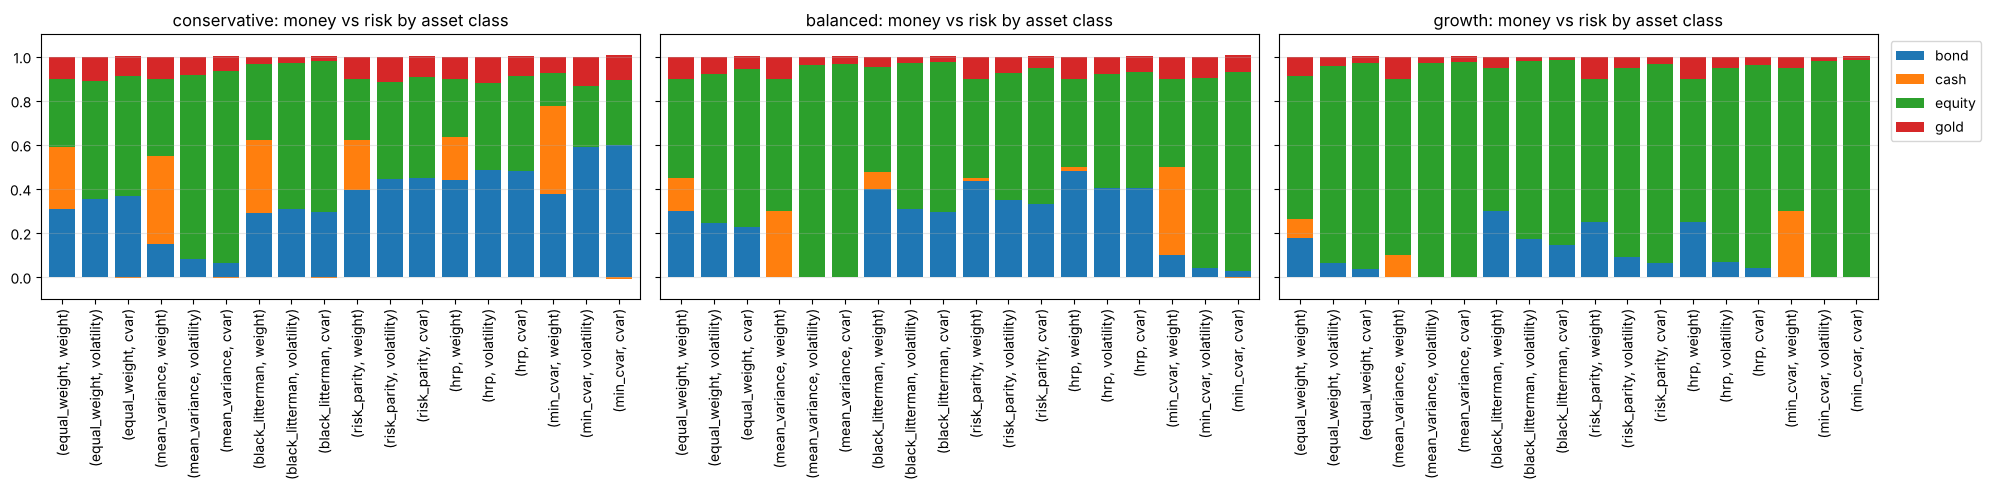

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, prof in zip(axes, ["conservative", "balanced", "growth"]):
    rows = {}
    for name, t in analysis["decomposition_by_class"].items():
        if name.startswith(prof + ":"):
            m = name.split(":")[1]
            for measure in ["weight", "share_of_volatility", "share_of_cvar"]:
                rows[(m, measure.replace("share_of_", ""))] = t[measure]
    pd.DataFrame(rows).T.plot.bar(stacked=True, ax=ax, legend=(prof == "growth"), width=0.8)
    ax.set_title(f"{prof}: money vs risk by asset class"); ax.set_ylim(-0.1, 1.1); ax.grid(True, alpha=0.3, axis="y")
axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

## Step 3: Historical stress tests

Today's portfolio held, without rebalancing, through five real crises, in TWD. `max_drawdown` is the worst fall inside the episode; it is compared with the client's maximum acceptable loss. The 2022 case matters most for conservative clients, because stocks and bonds fell together.

In [7]:
hs = analysis["historical_stress"]
dd = hs["max_drawdown"].unstack("scenario")
dd.index = pd.MultiIndex.from_tuples([tuple(n.split(":")) if ":" in n else ("benchmark", n) for n in dd.index])
dd.style.format("{:.1%}").background_gradient(cmap="Reds_r", axis=None)

In [8]:
hs[hs["beyond_limit"]][["total_return", "max_drawdown", "max_loss_limit", "months_to_recover"]].style.format(
    {"total_return": "{:.1%}", "max_drawdown": "{:.1%}", "max_loss_limit": "{:.0%}"}, na_rep="-")

And what the walk-forward portfolios *actually* did in the crises their backtest lived through (the 3-year window starts at the end of 2007, so it misses the first months of the 2008 crisis; `fully_covered` says whether the whole episode is inside the backtest):

In [9]:
analysis["realised_in_crises"].unstack("scenario")["realised_max_drawdown"].style.format("{:.1%}")

scenario,covid_crash,euro_debt_crisis,global_financial_crisis,inflation_shock_2022,taper_tantrum
portfolio,,,,,
balanced:black_litterman,-13.9%,-4.6%,-21.8%,-11.9%,-6.0%
balanced:equal_weight,-13.1%,-4.6%,-22.9%,-12.7%,-6.3%
balanced:hrp,-11.4%,-3.8%,-18.3%,-12.4%,-6.5%
balanced:mean_variance,-16.9%,-4.3%,-27.0%,-17.5%,-7.5%
balanced:min_cvar,-12.4%,-3.0%,-17.1%,-11.3%,-4.4%
balanced:risk_parity,-12.1%,-3.5%,-18.3%,-13.1%,-6.7%
conservative:black_litterman,-10.5%,-1.7%,-16.6%,-8.4%,-5.4%
conservative:equal_weight,-10.4%,-2.0%,-15.4%,-11.0%,-5.8%
conservative:hrp,-9.9%,-1.9%,-8.9%,-11.2%,-6.5%


## Step 4: Hypothetical shocks

Shocks applied instantly to today's weights. For the correlation scenario the number is a 1-in-20 bad year (1.645 x annual volatility) with every risky sleeve moving together at correlation 0.8, next to the same figure under normal correlations.

In [10]:
hyp = analysis["hypothetical_stress"]
loss = hyp["loss"].unstack("scenario")
display(loss.style.format("{:.1%}").background_gradient(cmap="Reds_r", axis=None))
hyp.xs("correlations_rise_to_0_8", level="scenario")[["loss", "normal_case", "max_loss_limit", "beyond_limit"]].style.format(
    {"loss": "{:.1%}", "normal_case": "{:.1%}", "max_loss_limit": "{:.0%}"})

scenario,correlations_rise_to_0_8,gold_down_20,taiwan_crash_twd_weakens,us_rates_up_2pp
portfolio,,,,
balanced:black_litterman,-20.7%,-1.0%,8.5%,-8.7%
balanced:equal_weight,-20.0%,-2.0%,2.5%,-7.3%
balanced:hrp,-20.8%,-2.0%,5.8%,-9.4%
balanced:mean_variance,-18.8%,-2.0%,-1.0%,-0.0%
balanced:min_cvar,-13.6%,-2.0%,6.0%,-1.5%
balanced:risk_parity,-22.1%,-2.0%,4.0%,-9.6%
conservative:black_litterman,-14.9%,-0.7%,6.1%,-6.3%
conservative:equal_weight,-16.1%,-2.0%,3.2%,-6.8%
conservative:hrp,-15.8%,-2.0%,5.5%,-7.5%


,loss,normal_case,max_loss_limit,beyond_limit
portfolio,,,,
equal_weight,-20.1%,-14.5%,nan%,False
sixty_forty,-24.0%,-18.2%,nan%,False
taiwan_equity_only,-31.0%,-31.0%,nan%,False
conservative:equal_weight,-16.1%,-11.5%,-10%,True
conservative:mean_variance,-13.9%,-11.2%,-10%,True
conservative:black_litterman,-14.9%,-11.2%,-10%,True
conservative:risk_parity,-16.0%,-11.5%,-10%,True
conservative:hrp,-15.8%,-11.5%,-10%,True
conservative:min_cvar,-11.0%,-8.1%,-10%,True


## Step 5: Goal probabilities

Three hypothetical clients, one per profile (amounts in TWD, nominal):

In [11]:
pd.DataFrame({p: {**cfg["clients"][p], "max_loss": cfg["profiles"][p]["max_loss"]} for p in cfg["clients"]}).T

,description,horizon_years,initial,monthly,goal,max_loss
conservative,Top up a home deposit in 5 years,5,1000000,10000,1700000,-0.1
balanced,Home deposit in 10 years,10,600000,15000,3000000,-0.2
growth,Retirement in 30 years,30,300000,10000,12000000,-0.3


Each client's portfolio options (the six methods of their profile, named `profile:method`, plus the three benchmarks for reference) are simulated 10,000 times over their horizon, two ways: a 12-month block bootstrap of the portfolio's walk-forward monthly returns after costs, and a fat-tailed Student-t fitted to the same history. `bad_case_years_to_goal` is the time by which 90% of simulated futures have reached the goal.

In [12]:
goals = analysis["goals"]
view = goals[["p_reach_goal", "median_wealth", "p5_wealth", "p95_wealth", "p_loss_beyond_limit",
              "bad_case_years_to_goal", "p_reach_goal_more_monthly", "p_reach_goal_later"]]
view.style.format({"p_reach_goal": "{:.0%}", "p_loss_beyond_limit": "{:.0%}", "p_reach_goal_more_monthly": "{:.0%}",
                   "p_reach_goal_later": "{:.0%}", "median_wealth": "{:,.0f}", "p5_wealth": "{:,.0f}",
                   "p95_wealth": "{:,.0f}", "bad_case_years_to_goal": "{:.1f}"})

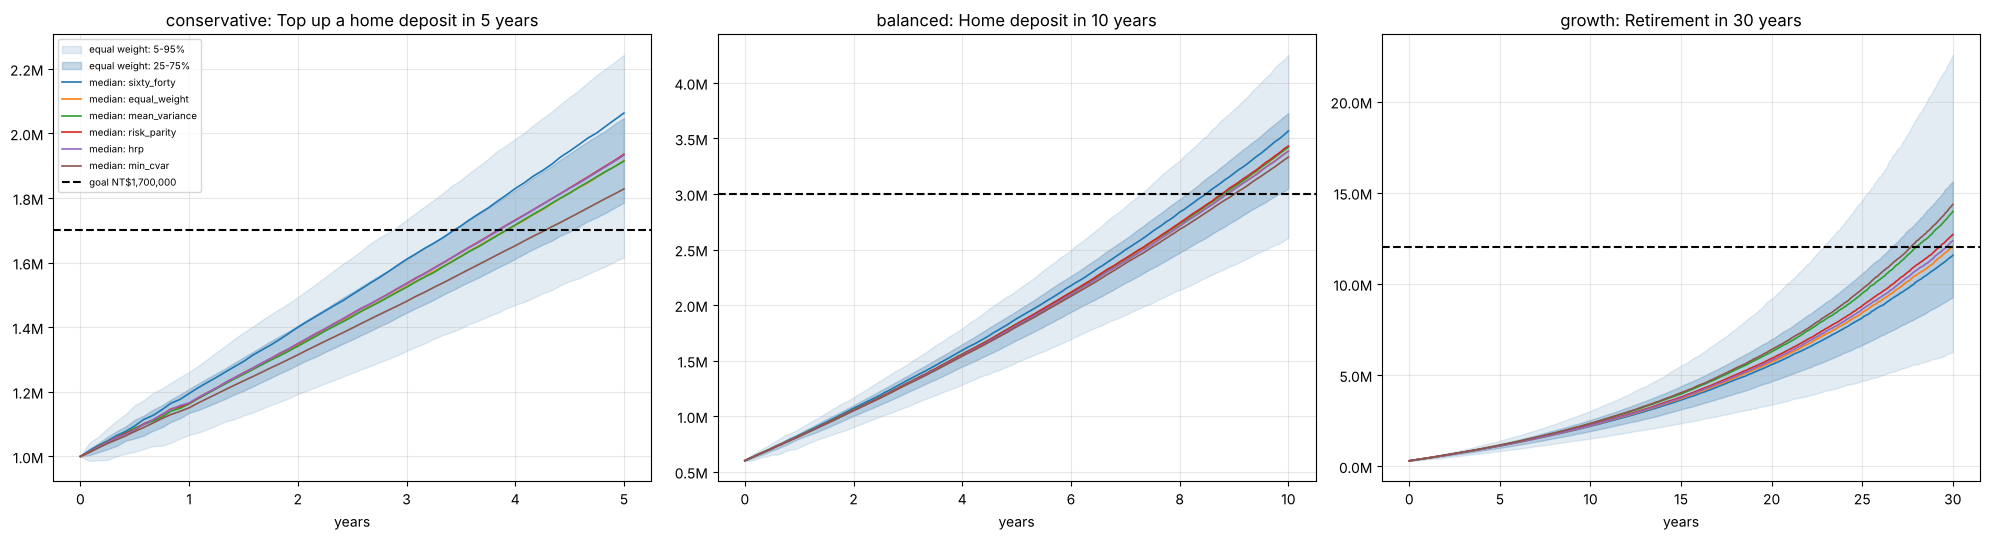

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, prof in zip(axes, cfg["clients"]):
    client = Client.from_config(cfg, prof)
    years = np.arange(int(client.horizon_years * 12) + 1) / 12
    q = analysis["fans"][(prof, f"{prof}:equal_weight")]["bootstrap"]
    ax.fill_between(years, q[0], q[4], alpha=0.15, color="steelblue", label="equal weight: 5-95%")
    ax.fill_between(years, q[1], q[3], alpha=0.3, color="steelblue", label="equal weight: 25-75%")
    for (p, name), fan in analysis["fans"].items():
        if p == prof and name.split(":")[-1] in ("equal_weight", "mean_variance", "risk_parity", "hrp", "min_cvar", "sixty_forty")                 and name != "equal_weight":
            ax.plot(years, fan["bootstrap"][2], label=f"median: {name.split(':')[-1]}", linewidth=1.2)
    ax.axhline(client.goal, color="black", linestyle="--", label=f"goal NT${client.goal:,.0f}")
    ax.set_title(f"{prof}: {client.description}"); ax.set_xlabel("years"); ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [14]:
tables = {"compliance": compliance, "sharpe_comparison": sharpe_cmp, **tables_for_saving(analysis)}
run_dir = save_run(results, summary, cfg, data, tables=tables)
print("Saved to", run_dir)

Saved to results/phase3_risk_847159c84c0e_570bdef9e8ea_dev


## Step 6: Reproducibility check

Re-run the risk analysis from the same results and check every table is identical (the Monte Carlo is seeded from the config).

In [15]:
again = run_risk_analysis(cfg, data, results)
for k in ["risk_summary", "historical_stress", "hypothetical_stress", "goals"]:
    pd.testing.assert_frame_equal(analysis[k], again[k], check_exact=True)
print("Identical: Phase 3 tables reproduce exactly.")

Identical: Phase 3 tables reproduce exactly.


## Findings

*From the run above (snapshot `570bdef9e8ea`, development data to 22 Oct 2024; today's portfolios as of 30 Sep 2024).*

- **How bad can it get:** replaying today's weights, 2008 cost 60/40 -26.5% and 100% Taiwan equity -61.7%; the conservative min-CVaR portfolio lost at most -5.3% in any replayed crisis. A 2-point rate rise costs up to -9.8%.
- **What drives the risk:** equities. 60/40 has 60% of its money and 75% of its volatility in equities; the conservative equal-weight portfolio 31% and 53%.
- **Goal probabilities:** 85-90% for the conservative client and 74-83% for the balanced client whatever the method; for the 30-year growth client 46% (60/40) to 68% (min-CVaR). Tail estimates depend on the simulation: chance of a fall beyond -30% for growth clients 23%-56% (bootstrap) vs 7%-24% (Student-t).
- **The CVaR variant:** the only method that kept the conservative client within -10% (worst drawdown -6.0% / -5.9% for the 3/5-year windows). Its 3 "significant" Sharpe wins out of 72 comparisons are about what chance alone produces (~7).
- **What failed:** the conservative profile's own numbers do not fit together (7% volatility implies a 11.5% bad year against a -10% limit), and under a correlation shock every conservative portfolio breaks its limit.

## FINAL: hold-out evaluation (run once, at the very end)

This opens the last two years of data, which no method or setting has seen, and evaluates every method and benchmark on them with the walk-forward portfolios carried over from the development period. **Run it only once, after everything is frozen.** If anything is changed after this, the hold-out is no longer an out-of-sample test. Every opening is logged in `results/holdout_log.jsonl`.

In [16]:
RUN_HOLDOUT = False

if RUN_HOLDOUT:
    from portfolio_engine.backtest import evaluate_holdout
    holdout_summary, holdout_results, holdout_dir = evaluate_holdout(cfg, snapshot_dir=SNAPSHOT)
    print("Saved to", holdout_dir)
    display(holdout_summary[["start", "end", "ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover_per_year"]])
else:
    print("Hold-out still locked.")

Hold-out still locked.
